# Sim-to-real for the TacTip rig: a walkthrough

This notebook goes through what has been built and tried so far, one experiment at a time. Each section says **what the question was**, **what was done**, and **what the numbers mean**. Run the cells in order. Nothing here trains anything long: it loads the sessions and the models you already have, and re-computes the checks on a subsample.

**The goal.** The physical rig and its simulated copy in TacTip-gym make the same motions over the same 3D-printed textures. Every real sample has a simulated twin. From those pairs we want a *mapping* between what the simulated TacTip senses and what the real one senses, in both directions:

* **sim → real**: give a policy trained in simulation what the real sensor *would* see.
* **real → sim**: turn real readings into simulated ones, so a policy trained in simulation can run on the real sensor.

**Words used below**

| Word | Meaning |
|---|---|
| session | one recording run with `rig_dataset collect`: a folder with `meta.json` and one `.npz` per trajectory |
| trajectory | one motion (press, stroke, circle, ...) cut into waypoints 0.5 mm apart |
| sample | one waypoint: both rigs there and still, one reading from each |
| untouched frames | a trajectory's first frames, while the sensor is still above the block |
| normalised MSE | squared error ÷ the data's variance: **1 = no better than always guessing the average, 0 = perfect** |
| corr | correlation between two signals: 1 = they rise and fall together, 0 = unrelated |

## 0. Setup

Set the paths to your session, its re-simulated copy and the models. The defaults are the ones used so far.

In [1]:
import json, os
import numpy as np
import matplotlib.pyplot as plt

DATA    = "/home/Dexter/Documents/GitHub/Rig-controller/data"
SESSION = os.path.join(DATA, "session_20261117_104611")          # the recording
RESIM   = SESSION + "_resim"                                     # its re-simulated copy
TG      = "/home/Dexter/Documents/GitHub/TacTip-gym"             # where the models were saved
IMAGE_MODEL = os.path.join(TG, "models/sim2real")                 # image mapping (experiment 2)
PIN_MAPS    = {"linear": os.path.join(TG, "models/pins"),         # marker maps (experiment 6)
               "mlp":    os.path.join(TG, "models/pins_mlp")}
EVERY = 4        # use every 4th sample in the checks below, to keep them quick

from tactip_mujoco_gym.sim2real.resim import read_meta, traj_arrays
from tactip_mujoco_gym.sim2real import PairedData, MarkerPairs, load_marker_map
from tactip_mujoco_gym.sim2real.paired import describe_pairing, Preprocess

meta = read_meta(SESSION)
rows = meta["trajectories"]
print(f"{len(rows)} trajectories, {sum(r['samples'] for r in rows)} samples")
print("kinds:", sorted({r['kind'] for r in rows}))
print("calibration:", (meta.get("calibration") or {}).get("pose_map", {}).get("kind"),
      "made", (meta.get("calibration") or {}).get("pose_map", {}).get("created"))

320 trajectories, 18320 samples
kinds: ['circle', 'figure8', 'press', 'ramp_stroke', 'random', 'spiral', 'stroke', 'tap', 'zigzag']
calibration: offset made 2026-11-17T10:35:30


## 1. What one sample looks like

**Question:** what is actually stored?

Each trajectory file holds, per sample, the simulated TacTip's camera image, the simulated markers' movement (mm), the real TacTip's camera image (the RealSense colour stream, stored BGR), the RealSense depth image, and the waypoint (x, y, and depth below the block's top; negative = above it).

Below: a press trajectory's untouched frame and its deepest frame, for both sensors.

texture_01/traj_0003_m003_r0_press.npz {'waypoint': (15, 3), 'phase': (15,), 'time': (15,), 'sim_pose': (15, 3), 'sim_markers': (15, 71, 3), 'sim_force': (15,), 'sim_tactip': (15, 240, 240, 3), 'real_steps': (15, 3), 'real_tactip': (15, 480, 640, 3), 'depth': (15, 480, 640), 'real_pins_xy': (15, 132, 2), 'real_pins_ok': (15, 132), 'real_pins_z': (15, 132), 'real_pins': (15, 132, 3)}


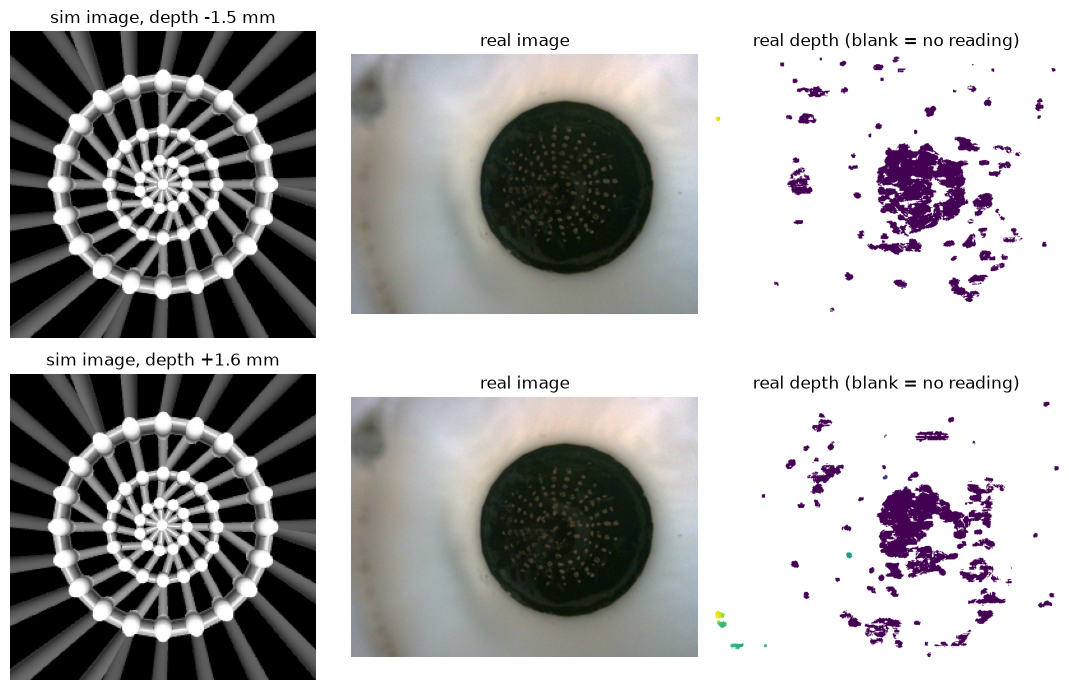

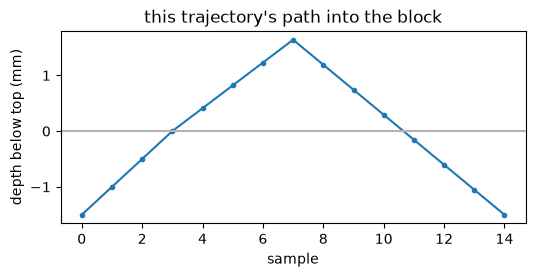

In [2]:
row = next(r for r in rows if r["kind"] == "press")
a = traj_arrays(SESSION, row)
print(row["file"], {k: v.shape for k, v in a.items()})
depth = a["waypoint"][:, 2]
first, deepest = 0, int(np.argmax(depth))

fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for r_, i in enumerate((first, deepest)):
    ax[r_, 0].imshow(a["sim_tactip"][i]);               ax[r_, 0].set_title(f"sim image, depth {depth[i]:+.1f} mm")
    ax[r_, 1].imshow(a["real_tactip"][i][..., ::-1]);   ax[r_, 1].set_title("real image")
    if "depth" in a:
        d = a["depth"][i].astype(float); d[d == 0] = np.nan
        ax[r_, 2].imshow(d, cmap="viridis");          ax[r_, 2].set_title("real depth (blank = no reading)")
for x in ax.ravel(): x.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 2.5))
plt.plot(depth, ".-"); plt.axhline(0, color="0.7")
plt.ylabel("depth below top (mm)"); plt.xlabel("sample"); plt.title("this trajectory's path into the block")
plt.show()

## 2. Experiment: map whole images (sim image ↔ real image)

**Idea:** one autoencoder compresses simulated images to a short code, another compresses real images, and two small networks translate between the codes (`train-mapping`).

**What happened:** each autoencoder learned its own images, but the translation did not: sim → real scored **~1.0**, no better than always predicting the average real image.

The cell below shows the stored scores, if you still have that model. Then it shows one of the reasons: the real camera's **brightness drifts** from trajectory to trajectory, even when nothing touches the sensor. The simulator can't know about that, so the mapping can't predict it.

image mapping scores (normalised MSE, 1 = average): {'samples': 2000, 'sim2real_nmse': 0.9963899254798889, 'sim2real_psnr_db': 38.81409454345703, 'real_rec_nmse': 0.36355623602867126, 'sim_rec_nmse': 0.09893935173749924, 'real2sim_nmse': 0.8514302968978882}


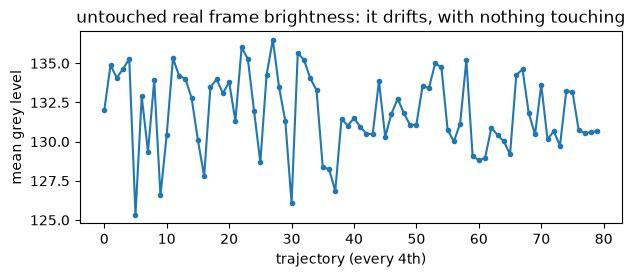

spread of untouched brightness: 2.5 grey levels


In [3]:
cfg_path = os.path.join(IMAGE_MODEL, "mapping.json")
if os.path.exists(cfg_path):
    cfg = json.load(open(cfg_path))
    print("image mapping scores (normalised MSE, 1 = average):", cfg["info"].get("metrics"))
else:
    print("no image mapping saved at", IMAGE_MODEL)

# the untouched real frame's brightness, trajectory by trajectory
bright = []
for r in rows[::4]:
    x = traj_arrays(SESSION, r, ("real_tactip",))["real_tactip"]
    bright.append(x[0].mean())
plt.figure(figsize=(7, 2.5))
plt.plot(bright, ".-"); plt.xlabel("trajectory (every 4th)"); plt.ylabel("mean grey level")
plt.title("untouched real frame brightness: it drifts, with nothing touching")
plt.show()
print(f"spread of untouched brightness: {np.std(bright):.1f} grey levels")

**Fix:** compare every real image with its own trajectory's untouched frames (`--reference trajectory`, now the default). The mapping then sees *what contact changed*, not the lighting that day.

## 3. Experiment: do the real images follow the simulated ones? (pairing check)

**Question:** before training anything, is there anything to learn? For every sample we measure how much the real image changed from untouched, and how much the simulated one did. If the rigs really made the same contact, these two numbers should rise and fall together (**corr** near 1).

We compare the raw images with **Sobel edges** (the pins' outlines), which drop the overall brightness and highlight small pin shifts.

In [4]:
quiet = lambda *a: None
checks = {}
for name, kw in {"raw images, 64 px": dict(),
                 "sobel edges, 128 px": dict(filter="sobel", real_size=(128, 128))}.items():
    d = PairedData.load(SESSION, every=EVERY, log=quiet, **kw)
    checks[name] = d
    p = d.pairing[0]
    print(f"{name:22s} corr {p['corr']:+.2f}   contact change {p['real_snr']:.1f}x noise   "
          f"real starts changing {p['onset_mm']:+.2f} mm vs sim")

raw images, 64 px      corr +0.31   contact change 1.4x noise   real starts changing -0.22 mm vs sim
sobel edges, 128 px    corr +0.58   contact change 1.8x noise   real starts changing -1.19 mm vs sim


**Reading it:** with Sobel edges the correlation roughly doubled (about 0.3 → 0.57 on the full session). "Contact change" is how far contact moves the real image above the camera's own frame-to-frame noise. Close to 1× means contact is barely visible. A negative "starts changing" means the real sensor responds at a *shallower* commanded depth than the simulated one: it sat lower than the simulated one, which is a height (z) calibration error.

The plot shows this for a few trajectories: blue is the simulated change, red the real change (each scaled), and dashed is the commanded depth.

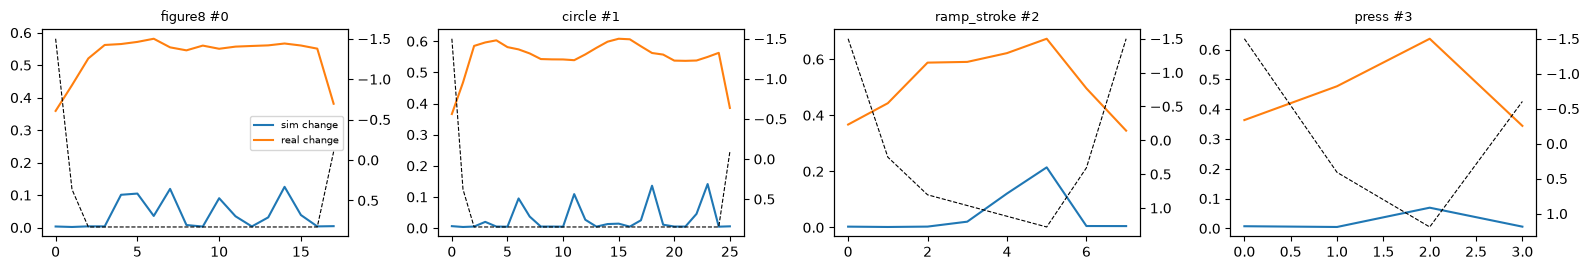

In [5]:
d = checks["sobel edges, 128 px"]
ks = np.unique(d.traj[d.phase == 1])[:4]
fig, ax = plt.subplots(1, len(ks), figsize=(4 * len(ks), 2.8))
for x, k in zip(np.atleast_1d(ax), ks):
    j = d.traj == k
    x.plot(d.sim_signal[j] / d.sim_signal.max(), label="sim change")
    x.plot(d.real_signal[j] / d.real_signal.max(), label="real change")
    x2 = x.twinx(); x2.plot(d.depth[j], "k--", lw=0.8); x2.invert_yaxis()
    x.set_title(f"{d.rows[k]['kind']} #{k}", fontsize=9)
np.atleast_1d(ax)[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Experiment: the real pins as coordinates (`extract-pins`)

**Idea:** instead of pixels, track the white pins. Each pin gets x, y in the colour image and z from the depth image (where the depth camera has a reading: it sits close to the skin, so only some pins have one). Movement is measured from the trajectory's untouched frames, so lighting drift drops out.

**Result on your session:** 132 pins, followed in about 97% of frames; depth at a pin about half the time; depth noise about 0.1 mm against about 0.85 mm of movement on a deep press.

132 pins, pitch 12.5 px, depth at pins 52% of the time; RealSense D405: colour from the depth imager


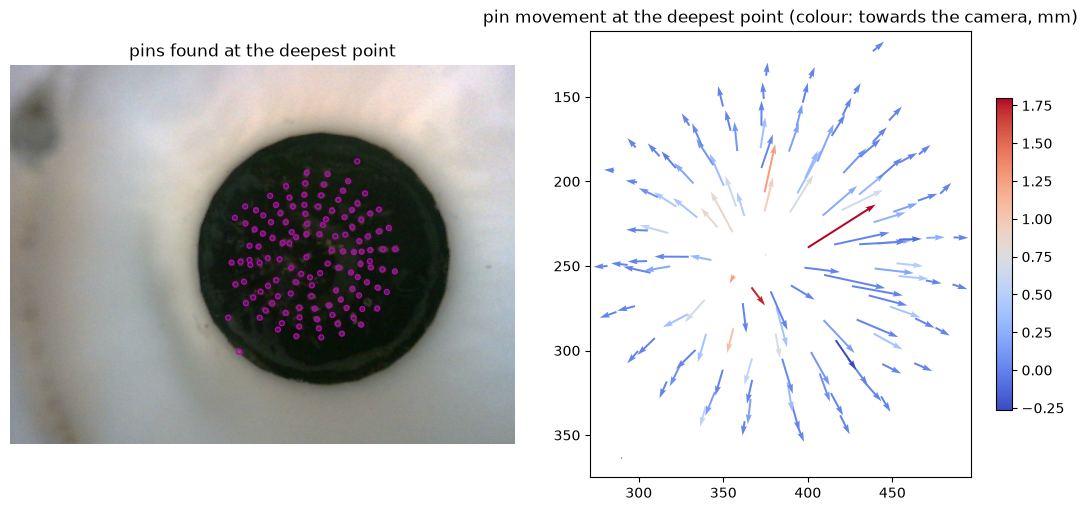

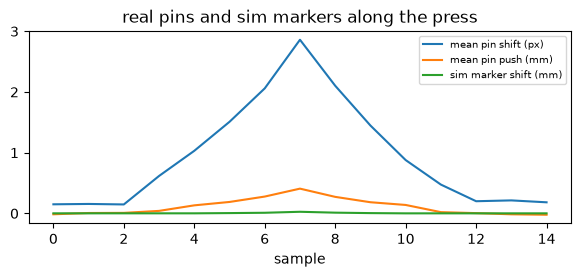

In [6]:
pins_meta = json.load(open(os.path.join(SESSION, "pins", "pins.json")))
print(f"{pins_meta['pins']} pins, pitch {pins_meta['pitch_px']:.1f} px, depth at pins "
      f"{pins_meta['depth_coverage']:.0%} of the time; {pins_meta['registration']}")

a = traj_arrays(SESSION, row)            # the press from section 1, now with its pins
xy, ok, mv = a["real_pins_xy"], a["real_pins_ok"], a["real_pins"]
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(a["real_tactip"][deepest][..., ::-1])
ax[0].scatter(*xy[deepest][ok[deepest]].T, s=12, facecolors="none", edgecolors="m")
ax[0].set_title("pins found at the deepest point"); ax[0].axis("off")
q = ax[1].quiver(xy[0][:, 0], xy[0][:, 1], mv[deepest][:, 0], -mv[deepest][:, 1],
                 np.nan_to_num(-mv[deepest][:, 2]), cmap="coolwarm", scale=40)
ax[1].invert_yaxis(); ax[1].set_aspect("equal")
ax[1].set_title("pin movement at the deepest point (colour: towards the camera, mm)")
plt.colorbar(q, ax=ax[1], shrink=0.7); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 2.5))
plt.plot(np.nanmean(np.linalg.norm(mv[..., :2], axis=2), axis=1), label="mean pin shift (px)")
plt.plot(np.nanmean(-mv[..., 2], axis=1), label="mean pin push (mm)")
plt.plot(np.linalg.norm(a["sim_markers"], axis=2).mean(axis=1), label="sim marker shift (mm)")
plt.legend(fontsize=7); plt.xlabel("sample"); plt.title("real pins and sim markers along the press"); plt.show()

## 5. Experiment: re-simulating the trials, and the height error (`resim`)

**Idea:** every recorded trajectory can be re-run in the simulator with the same texture, path and samples. This records simulated readings the original run didn't have (the markers and a simulated depth camera), and the simulated sensor can be pushed deeper or shallower to cancel a calibration height error.

**The fit:** for a range of offsets, it compares the depth where the simulated markers start moving with the depth where the real images start changing (the *gap*), and how well the two correlate. On your data the gap never reached zero. The real images start changing earlier than any offset explains, perhaps from vibration or light changing as the sensor nears the block. So the offset was chosen by correlation.

offset used: 2.5 mm (+ = simulated sensor deeper); recorded: ['markers', 'depth']


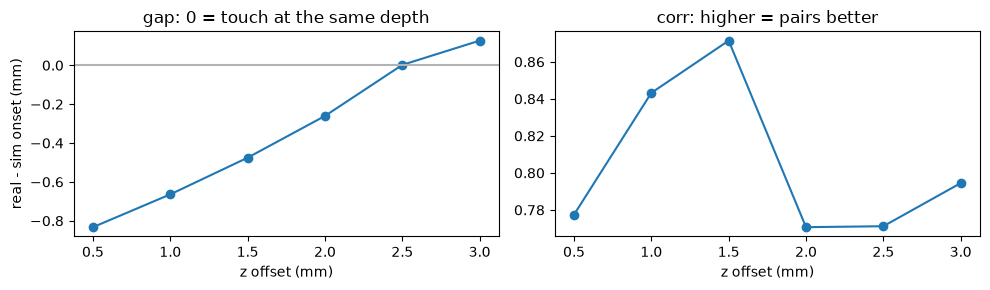

In [7]:
rm = read_meta(RESIM)["resim"]
print("offset used:", rm["z_offset_mm"], "mm (+ = simulated sensor deeper); recorded:", rm["record"])
fit = rm.get("fit")
if fit:
    z = sorted(fit, key=float)
    gap = [fit[k]["onset_gap_mm"] for k in z]; cor = [fit[k]["corr"] for k in z]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot([float(k) for k in z], gap, "o-"); ax[0].axhline(0, color="0.7")
    ax[0].set_xlabel("z offset (mm)"); ax[0].set_ylabel("real - sim onset (mm)"); ax[0].set_title("gap: 0 = touch at the same depth")
    ax[1].plot([float(k) for k in z], cor, "o-"); ax[1].set_xlabel("z offset (mm)"); ax[1].set_title("corr: higher = pairs better")
    plt.tight_layout(); plt.show()

## 6. Experiment: the marker-to-marker map (`train-marker-map`)

**Idea:** learn the simulated markers' movement (71 markers × 3, mm) ↔ the real pins' movement (132 pins × x, y px, z mm), in both directions. It is trained on the re-simulated session, so the simulated side has the height correction. Validation uses whole motions the map never saw.

**Results so far**

| | sim → real | real → sim |
|---|---|---|
| image mapping (exp. 2) | ~1.0 | — |
| linear marker map | 0.48 | 0.77 |
| MLP marker map | **0.42** (pins off 0.62 px, 0.29 mm in z) | **0.74** |

So sim → real explains about 58% of the real pins' movement, and real → sim about a quarter. The cells below recompute this on the held-out motions and show one example.

In [8]:
pairs = MarkerPairs.load(RESIM, use_z=True, log=quiet)
tr, va = pairs.split(0.15, seed=0)            # the same held-out motions as in training
maps = {k: load_marker_map(p) for k, p in PIN_MAPS.items() if os.path.exists(p)}
for k, m in maps.items():
    mt = m.evaluate(pairs, va)
    print(f"{k:7s} sim->real {mt['sim2real_nmse']:.3f}  real->sim {mt['real2sim_nmse']:.3f}  "
          f"(pins off {mt['sim2real_rmse_xy_px']:.2f} px, {mt.get('sim2real_rmse_z_mm', float('nan')):.2f} mm z)")

linear  sim->real 0.483  real->sim 0.774  (pins off 0.66 px, 0.30 mm z)
mlp     sim->real 0.420  real->sim 0.740  (pins off 0.62 px, 0.29 mm z)


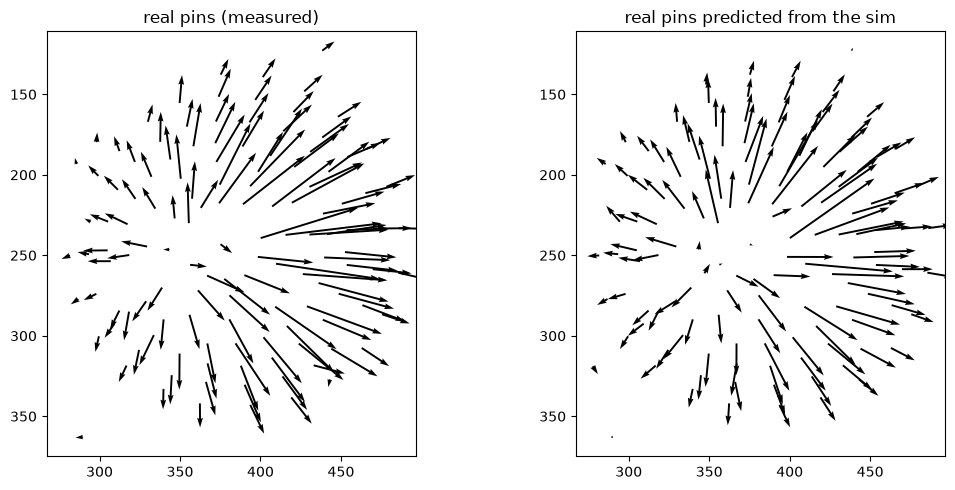

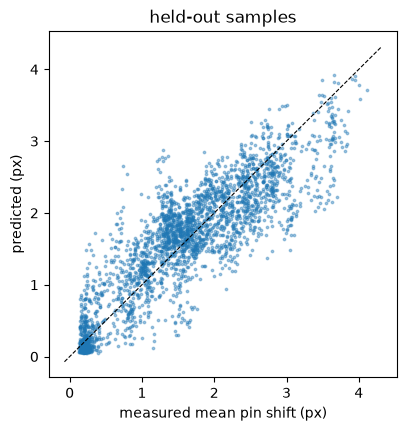

In [9]:
m = maps.get("mlp") or next(iter(maps.values()))
i = va[np.argmax(np.nanmean(np.linalg.norm(np.nan_to_num(pairs.real[va][..., :2]), axis=2), axis=1))]  # a big press
pred = m.sim_to_real(pairs.sim[i]); true = pairs.real[i]
rest = np.asarray(pairs.rest_px)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for x, v, t in ((ax[0], true, "real pins (measured)"), (ax[1], pred, "real pins predicted from the sim")):
    x.quiver(rest[:, 0], rest[:, 1], v[:, 0], -v[:, 1], scale=40)
    x.invert_yaxis(); x.set_aspect("equal"); x.set_title(t)
plt.tight_layout(); plt.show()

# every held-out sample: how far the pins moved, measured vs predicted
P = m.sim_to_real(pairs.sim[va]); R = pairs.real[va]
plt.figure(figsize=(4.5, 4.5))
plt.scatter(np.nanmean(np.linalg.norm(np.nan_to_num(R[..., :2]), axis=2), axis=1),
            np.mean(np.linalg.norm(P[..., :2], axis=2), axis=1), s=3, alpha=0.4)
lim = plt.xlim(); plt.plot(lim, lim, "k--", lw=0.8)
plt.xlabel("measured mean pin shift (px)"); plt.ylabel("predicted (px)"); plt.title("held-out samples")
plt.show()

**Reading it:** points on the dashed line are perfect predictions. The map gets the size of a press right broadly but compresses the extremes. That fits a sim → real score of about 0.4.

## 7. Using it in the simulator (optional, needs MuJoCo)

The trained map is an input in every environment: `real_pins` gives a policy the real pins' predicted movement.

In [10]:
RUN_GYM = False        # set True to try it
if RUN_GYM:
    import gymnasium as gym, tactip_mujoco_gym  # noqa
    env = gym.make("TacRig-v0", sensors={"real_pins": {"model": PIN_MAPS["mlp"]}},
                   obs_modes=["real_pins"], obs_format="dict")
    obs, _ = env.reset(seed=0)
    print(obs["real_pins"].shape)
    env.close()

## Summary

1. **Whole-image mapping failed** (score ~1.0). The real camera's drift and old calibration meant real images didn't follow the simulated ones.
2. **The pairing check** measures that before training. Sobel edges and comparison with untouched frames improved it, but contact still barely shows in the raw pixels.
3. **Pins as coordinates** work: 132 pins tracked about 97% of the time, with depth for about half.
4. **The marker map** gives a usable sim → real (score 0.42, pins within about 0.6 px) and a weak real → sim (0.74).
5. **The main limit is the data pairing, not the model.** The networks stopped improving after a few epochs. The simulated and real presses don't quite happen at the same depth, and the real images change before contact.

**Next:** record a new session with the height corrected and a longer settle (`rig_dataset collect --settle 0.3`). Then repeat sections 3–6 on it and compare.